---
title: "Лекція 1. Складні системи як об'єкт математичного моделювання"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: callout-note
## Примітка

Ця лекція відповідає *Темі 1 «Складні системи як об'єкт математичного моделювання»* НРП освітнього компонента «Математичне моделювання складних систем».

Курс продовжує освітню вертикаль після бакалаврської дисципліни «Моделювання систем». Тому базові поняття математичної моделі, класифікації моделей та обчислювального експерименту вважаємо вхідними результатами навчання і актуалізуємо лише там, де це необхідно для переходу до рівня PhD.

Основний акцент лекції -- не на тому, *як застосувати відомий клас моделей*, а на тому, *як розпізнати складність досліджуваної системи, обрати адекватний рівень її опису та побудувати модель як інструмент отримання нового наукового знання*.
:::


# Вступ

У бакалаврському курсі питання моделювання природно починається з поняття системи, моделі та процесу переходу від об'єкта до його формалізованого представлення.

На рівні PhD цього вже недостатньо.

Нас цікавить інше питання:

> *Що змінюється в методології математичного моделювання, коли об'єктом дослідження стає складна система?*

Складність тут не означає просто «велика», «важка для обчислення» або «така, що має багато компонентів» [@mitchell2009; @ladyman2013; @ladymanWiesner2020]. Система може містити мільйони однотипних незалежних елементів і залишатися концептуально простою. І навпаки -- система з відносно невеликою кількістю компонентів може демонструвати нелінійність, зворотні зв'язки, адаптацію та поведінку, яку неможливо пояснити простим аналізом її частин.

Тому центральна проблема цієї лекції:

$$
\boxed{
\text{Components}
+
\text{Interactions}
+
\text{Organization}
\not\Rightarrow
\text{trivial system behaviour}
}
$$

Саме цей розрив між локальними правилами та поведінкою системи в цілому робить *складні системи (complex systems)* особливим об'єктом математичного моделювання.


# Тема 1. Складні системи як об'єкт математичного моделювання

## 1. Від системи до складної системи

Нехай систему подано як множину компонентів

$$
V=\{v_1,v_2,\ldots,v_n\},
$$

між якими існують взаємодії

$$
E=\{e_{ij}\}.
$$

На найпростішому рівні можна записати

$$
S=(V,E).
$$

Але для складної системи цього опису недостатньо. Її стан змінюється в часі, взаємодії можуть залежати від станів компонентів, структура зв'язків -- перебудовуватися, а макроскопічна поведінка -- виникати як результат великої кількості локальних взаємодій.

Тому корисніше мислити систему як

$$
S(t)=\bigl(V(t),E(t),X(t),\Theta,\mathcal{R},\mathcal{E}(t)\bigr),
$$

де:

- $V(t)$ -- компоненти системи;
- $E(t)$ -- структура взаємодій;
- $X(t)$ -- вектор стану;
- $\Theta$ -- параметри;
- $\mathcal{R}$ -- правила або механізми еволюції;
- $\mathcal{E}(t)$ -- середовище, з яким система взаємодіє.

Це ще не універсальне формальне означення complex system. Це *робочий каркас*, який показує, чому для складної системи недостатньо просто перерахувати її складові.


## 2. Complex і complicated -- не одне й те саме

Українське слово «складний» приховує важливу відмінність між двома англійськими поняттями:

- *ускладнена система (complicated system)*;
- *складна система (complex system)*.

| Ознака | Complicated | Complex |
|---|---|---|
| Кількість компонентів | може бути дуже великою | може бути великою або помірною |
| Декомпозиція | часто ефективна | може руйнувати суттєві властивості |
| Поведінка цілого | значною мірою випливає з частин | може виникати з взаємодій |
| Зворотні зв'язки | не обов'язково визначальні | часто принципові |
| Адаптація | зазвичай не є ключовою | часто присутня |
| Передбачуваність | потенційно висока за достатнього знання | може бути обмеженою принципово або практично |
| Типова проблема | інженерна складність | організаційно-динамічна складність |

Наприклад, сучасний процесор є надзвичайно *complicated*: він містить величезну кількість елементів, але його архітектура спроєктована так, щоб поведінка була контрольованою.

Соціальна мережа, екосистема, розподілена інформаційна система або популяція автономних агентів можуть бути *complex*: глобальна поведінка формується через взаємодії, зворотні зв'язки та адаптацію.


::: callout-important
## Ключова ідея

Кількість компонентів сама по собі не є критерієм складної системи.

Для моделювання важливіше запитати:

> *Чи можна пояснити поведінку системи, незалежно описавши її компоненти, чи пояснення потребує моделювання структури та динаміки їх взаємодій?*
:::


## 3. Основні ознаки складної системи

У різних предметних областях набори ознак відрізняються [@ladyman2013; @mitchell2009]. Для нашого курсу будемо використовувати не формальний чекліст, а систему взаємопов'язаних характеристик:

1. нелінійність;
2. взаємодія компонентів;
3. зворотні зв'язки;
4. емерджентність;
5. самоорганізація;
6. адаптивність;
7. гетерогенність;
8. відкритість;
9. багатомасштабність.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    C("Складна система")
    N("Нелінійність")
    I("Взаємодії")
    F("Зворотні зв'язки")
    E("Емерджентність")
    S("Самоорганізація")
    A("Адаптивність")
    H("Гетерогенність")
    O("Відкритість")
    M("Багатомасштабність")

    C --> N
    C --> I
    C --> F
    C --> E
    C --> S
    C --> A
    C --> H
    C --> O
    C --> M
```

Важливо: наявність однієї ознаки ще не робить систему complex. Методологічно значущою є їх *комбінація* та вплив на можливість пояснення, прогнозування і керування.


## 4. Нелінійність (nonlinearity)

Для лінійної системи діє принцип суперпозиції:

$$
F(\alpha x_1+\beta x_2)
=
\alpha F(x_1)+\beta F(x_2).
$$

У нелінійній системі загалом

$$
F(\alpha x_1+\beta x_2)
\neq
\alpha F(x_1)+\beta F(x_2).
$$

Це означає, що результат спільної дії факторів не обов'язково дорівнює сумі результатів їх окремої дії.

### Приклад

Нехай найпростіша динаміка задається логістичним відображенням:

$$
x_{t+1}=r x_t(1-x_t),
$$

де $x_t\in[0,1]$, а $r$ -- параметр.

Рівняння має лише одну змінну стану, але зі зміною $r$ система переходить від стаціонарної поведінки до коливань, каскаду біфуркацій і хаотичних режимів [@strogatz2015; @sayama2015].

Отже:

> *структурно проста математична модель може породжувати складну динаміку.*

Це важливе попередження проти ототожнення складності моделі зі складністю поведінки системи.


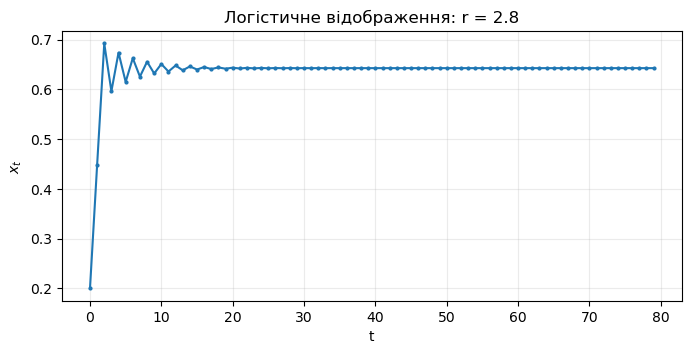

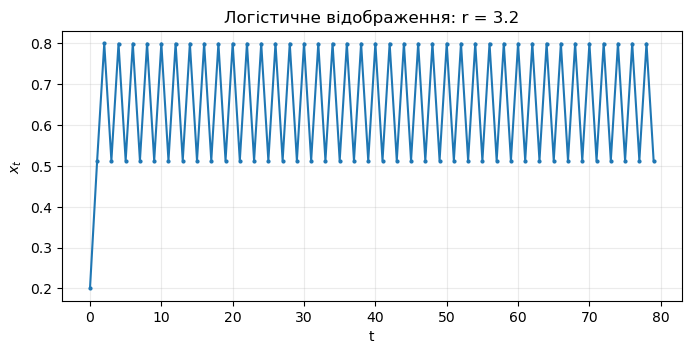

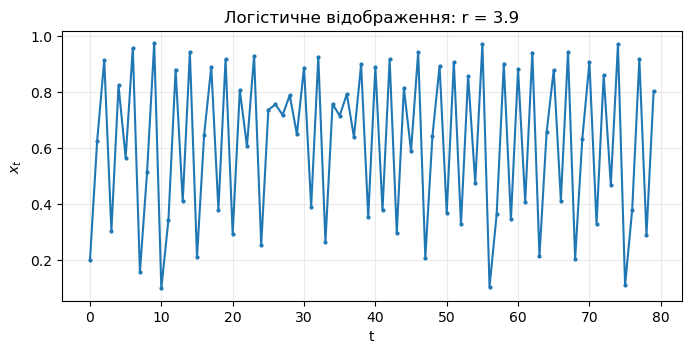

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def logistic_map(r, x0=0.2, n=80):
    """Обчислює траєкторію логістичного відображення."""
    x = np.empty(n)
    x[0] = x0
    for t in range(n - 1):
        x[t + 1] = r * x[t] * (1 - x[t])
    return x

# Порівняємо три режими тієї самої моделі.
for r in [2.8, 3.2, 3.9]:
    x = logistic_map(r)
    plt.figure(figsize=(8, 3.5))
    plt.plot(range(len(x)), x, marker="o", markersize=2)
    plt.xlabel("t")
    plt.ylabel("$x_t$")
    plt.title(f"Логістичне відображення: r = {r}")
    plt.grid(alpha=0.25)
    plt.show()


У цьому прикладі важливий не сам логістичний map як окремий алгоритм. Він демонструє методологічну тезу:

$$
\text{simple local rule}
\;\not\Rightarrow\;
\text{simple global dynamics}.
$$

На рівні PhD нас цікавить не лише отримана траєкторія, а питання:

- які режими поведінки існують;
- за яких значень параметрів відбуваються переходи;
- наскільки результат чутливий до початкових умов;
- чи є спостережувана складність властивістю моделі, реальної системи або чисельного алгоритму.

До останнього питання ми повернемося в Темі 3.


## 5. Взаємодія компонентів (interactions)

У багатьох складних системах суттєва інформація міститься не лише в станах компонентів, а й у *структурі взаємодій* [@sayama2015; @newman2018; @barabasi2016].

Нехай стан $i$-го компонента дорівнює $x_i(t)$. Тоді загальна динаміка може бути подана як

$$
\frac{dx_i}{dt}
=
f_i\left(
x_i,
\{x_j:j\in\mathcal{N}_i\},
\theta_i,
t
\right),
$$

де $\mathcal{N}_i$ -- множина компонентів, що впливають на $i$-й компонент.

У такому записі поведінка $x_i$ вже не визначається лише його власним станом.

Звідси принципове питання моделювання:

> *що саме потрібно моделювати -- компоненти, зв'язки між ними чи спільну еволюцію структури й станів?*

Це питання стане центральним у темах про складні мережі.


## 6. Зворотні зв'язки (feedback)

Зворотний зв'язок виникає тоді, коли результат процесу впливає на подальшу поведінку самого процесу.

У найпростішому вигляді:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'lineColor': '#536878'
}}}%%
flowchart LR
    X("Стан системи x(t)") --> P("Процес")
    P --> Y("Результат y(t)")
    Y -->|"feedback"| X
```

Розрізняють:

- *позитивний зворотний зв'язок (positive feedback)* -- підсилює відхилення або процес;
- *негативний зворотний зв'язок (negative feedback)* -- протидіє відхиленню та може стабілізувати систему.

Але в реальній complex system одночасно можуть діяти кілька контурів різного знака, масштабу й часової затримки.

Тому фраза «у системі є feedback» ще нічого не пояснює. Потрібно встановити *структуру контурів, їх часові масштаби та нелінійні взаємодії*.


## 7. Емерджентність (emergence)

*Емерджентність (emergence)* -- одна з центральних і водночас найбільш неоднозначних характеристик складних систем [@mitchell2009; @ladyman2013].

Робоче розуміння для математичного моделювання:

> *емерджентною називаємо макроскопічну властивість або режим поведінки, що виникає внаслідок взаємодій компонентів і не задається безпосередньо як властивість окремого компонента.*

Схематично:

$$
\{x_1,x_2,\ldots,x_n\}
+
\text{interactions}
\longrightarrow
Y_{\text{macro}}.
$$

Причому

$$
Y_{\text{macro}}
\neq
g(x_i)
$$

для будь-якого одного компонента $i$.

### Приклади

- синхронізація мережі осциляторів;
- формування спільнот у соціальній системі;
- колективний рух агентів;
- каскадне поширення інформації;
- затори в транспортній мережі;
- макроскопічна стійкість або крихкість розподіленої системи.

У кожному випадку дослідницький інтерес зміщується від окремого елемента до механізму переходу

$$
\text{micro interactions}
\rightarrow
\text{macro behaviour}.
$$


::: callout-warning
## Важливе методологічне застереження

Не кожна властивість, яку важко передбачити, є емерджентною.

Несподіваний результат може виникнути через:

- помилку реалізації;
- невдалий чисельний метод;
- недостатню точність;
- випадкові флуктуації;
- невдалу візуалізацію;
- артефакт дискретизації.

Тому твердження про emergence потребує *доказової процедури*, а не лише красивої симуляції.
:::


## 8. Самоорганізація (self-organization)

*Самоорганізація (self-organization)* означає виникнення впорядкованої структури або узгодженої поведінки без зовнішнього централізованого керування, який безпосередньо задає кінцеву конфігурацію [@mitchell2009; @sayama2015].

Умовно:

$$
\text{local rules}
+
\text{interactions}
+
\text{feedback}
\longrightarrow
\text{global organization}.
$$

Ключове слово тут -- *local*.

Якщо глобальну структуру безпосередньо задає центральний координатор, це не той механізм самоорганізації, який зазвичай цікавить complex systems science.

У комп'ютерних науках ця ідея виникає в:

- багатоагентних системах;
- розподілених алгоритмах;
- swarm intelligence;
- peer-to-peer системах;
- самоорганізованих мережах;
- моделях колективної поведінки.


## 9. Адаптивність (adaptivity)

*Адаптивність (adaptivity)* означає здатність компонентів або системи змінювати поведінку у відповідь на середовище, історію взаємодій або результати попередніх дій.

У загальному вигляді можна мати не лише

$$
X_{t+1}=F(X_t,\Theta),
$$

а

$$
X_{t+1}=F(X_t,\Theta_t),
$$

де самі параметри або правила змінюються:

$$
\Theta_{t+1}=G(\Theta_t,X_t,\mathcal{E}_t).
$$

Тоді система має *подвійну динаміку*:

1. змінюються стани;
2. змінюються механізми, які породжують ці стани.

Це суттєво ускладнює ідентифікацію та валідацію моделі: модель, яка добре описувала систему в одному режимі, може втратити адекватність після адаптації.


## 10. Гетерогенність (heterogeneity)

У спрощених моделях часто припускають, що всі компоненти одного типу однакові:

$$
\theta_i=\theta,\qquad i=1,\ldots,n.
$$

У складній системі це припущення може бути неприйнятним:

$$
\theta_i\neq\theta_j.
$$

Компоненти можуть відрізнятися за:

- параметрами;
- поведінковими правилами;
- доступною інформацією;
- ролями;
- ресурсами;
- положенням у структурі взаємодій.

Гетерогенність може бути не «шумом», який треба усереднити, а *механізмом формування макроскопічної поведінки*.

Саме тому вибір між індивідуальним, груповим та агрегованим описом є науковим рішенням, а не лише питанням зручності обчислень.


## 11. Відкритість системи (openness)

Реальна складна система зазвичай не існує ізольовано.

Вона обмінюється із середовищем:

- інформацією;
- ресурсами;
- енергією;
- агентами;
- зовнішніми впливами.

Позначимо стан системи $X(t)$ та зовнішній вплив $U(t)$. Тоді

$$
\dot X(t)=F(X(t),U(t),\Theta).
$$

Але для відкритої системи проблема полягає не лише в наявності $U(t)$.

Потрібно визначити:

> *де провести межу системи (system boundary)?*

Від відповіді залежить, що ми вважатимемо:

- внутрішньою змінною;
- параметром;
- зовнішнім впливом;
- шумом;
- частиною середовища.

Це вже безпосередній міст до Теми 2 -- концептуалізації та формалізації складної системи.


## 12. Багатомасштабність (multiscale nature)

Складна система часто має кілька просторових, часових або організаційних масштабів [@sayama2015; @radhakrishnan2021].

Наприклад:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    MI("Мікрорівень<br/>окремі компоненти")
    ME("Мезорівень<br/>групи / модулі / спільноти")
    MA("Макрорівень<br/>система в цілому")

    MI -->|"агрегування"| ME
    ME -->|"агрегування"| MA
    MA -.->|"обмеження / feedback"| ME
    ME -.->|"локальний контекст"| MI
```

Масштаби не обов'язково утворюють просту односторонню ієрархію. Макроскопічний стан може змінювати локальні правила, а локальні взаємодії -- формувати новий макрорежим.


# 13. Мікро-, мезо- та макрорівні опису

Для поглибленого самостійного опрацювання корисним є відкритий підручник Hiroki Sayama [*Introduction to the Modeling and Analysis of Complex Systems*](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/) [@sayama2015].

## 13.1. Мікрорівень (micro level)

На мікрорівні моделюємо окремі елементи:

$$
x_1(t),x_2(t),\ldots,x_n(t).
$$

Перевага -- можливість явно представляти гетерогенність і локальні взаємодії.

Недолік -- висока розмірність і ризик втратити пояснення за великою кількістю деталей.

## 13.2. Мезорівень (meso level)

Мезорівень описує проміжні структури:

- кластери;
- спільноти;
- модулі;
- підсистеми;
- функціональні групи.

Саме на цьому рівні часто стають видимими механізми, яких не видно ані на рівні окремого компонента, ані в глобальному середньому.

## 13.3. Макрорівень (macro level)

Макрорівень використовує агреговані змінні:

$$
Y(t)=G(X(t)).
$$

Наприклад, середній стан:

$$
\bar{x}(t)=\frac{1}{n}\sum_{i=1}^{n}x_i(t).
$$

Але середнє може приховати структуру.

Дві системи можуть мати однакове $\bar{x}$ і принципово різну внутрішню організацію.


### Приклад: однакове середнє -- різні системи

Розглянемо два набори станів:

$$
X^{(A)}=(0,0,0,0,1,1,1,1),
$$

$$
X^{(B)}=(0,1,0,1,0,1,0,1).
$$

В обох випадках

$$
\bar{x}=0.5.
$$

Якщо компоненти розміщені в мережі або просторі, система $A$ може утворювати два локальні домени, а система $B$ -- чергування станів.

Отже, агрегований показник зберігає одну характеристику і втрачає іншу.

Звідси:

$$
\boxed{
\text{рівень опису}
\;\text{визначає, яке знання модель здатна зберегти}
}
$$


# 14. Рівень опису -- це частина наукової гіпотези

Вибір micro/meso/macro не є лише технічним рішенням.

Якщо дослідник переходить від $X$ до агрегованої змінної $Y=G(X)$, він фактично висуває припущення:

> *інформація, втрачена при агрегуванні, не є критичною для дослідницького питання.*

Це припущення може виявитися хибним.

Тому на рівні PhD потрібно вміти обґрунтувати:

1. чому обрано саме цей рівень абстракції;
2. які механізми він зберігає;
3. які механізми він ігнорує;
4. чи можуть втрачені деталі змінити науковий висновок.

Це один із ключових переходів від навчального моделювання до *model-based scientific inquiry*.


# 15. Модель як відображення, а не копія реальності

Нехай реальна система позначена $\mathcal{S}$, а модель -- $\mathcal{M}$.

Процес моделювання можна подати як відображення

$$
\Phi:\mathcal{S}\rightarrow\mathcal{M}.
$$

Це відображення неминуче:

- відбирає одні властивості;
- ігнорує інші;
- вводить припущення;
- визначає масштаб;
- задає змінні й параметри;
- встановлює форму взаємодій.

Тому модель не є «зменшеною копією» системи.

Вона є *цілеспрямованою абстракцією*.


::: callout-important
## Модель завжди будується для мети

Питання

> «Чи правильна ця модель?»

у багатьох випадках поставлене некоректно.

Методологічно сильніше запитання:

> *«Чи є ця модель достатньо адекватною для конкретного дослідницького питання, у визначеній області застосовності та з урахуванням її припущень і невизначеностей?»*

Саме ця логіка згодом приведе нас до *верифікації та валідації (Verification & Validation, V&V)*, *достовірності моделі (model credibility)* та *області застосовності (domain of validity)* [@oberkampfRoy2010].
:::


# 16. Чому «детальніша модель» не обов'язково краща

Нехай модель має складність $C(\mathcal{M})$, а її здатність відповідати на дослідницьке питання -- умовну корисність $U(\mathcal{M}\mid RQ)$.

Немає загального закону

$$
C(\mathcal{M})\uparrow
\quad\Rightarrow\quad
U(\mathcal{M}\mid RQ)\uparrow.
$$

Надмірна деталізація може:

- збільшити кількість невідомих параметрів;
- погіршити ідентифікованість;
- ускладнити калібрування;
- збільшити обчислювальну вартість;
- зробити механізм менш інтерпретованим;
- створити ілюзію реалізму без збільшення доказової сили.

Тому мета -- не максимальна деталізація, а *достатня складність моделі для поставленого наукового питання*.


# 17. Від складної системи до модельного дослідження

Для PhD-дослідження корисно мислити не окремою моделлю, а ланцюгом:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    R("Реальна складна система")
    Q("Дослідницьке питання")
    C("Концептуальна модель")
    M("Математична модель")
    K("Комп'ютерна модель")
    E("Обчислювальний експеримент")
    O("Model output")
    V("Evidence")
    I("Scientific inference")

    R --> Q
    Q --> C
    C --> M
    M --> K
    K --> E
    E --> O
    O --> V
    V --> I
```

Ця схема принципово відрізняється від спрощеної логіки

$$
\text{Model}\rightarrow\text{Result}.
$$

Наукове дослідження потребує обґрунтувати *кожний перехід* [@oberkampfRoy2010; @smith2024].


## 17.1. Model output ≠ scientific evidence

Число, графік або траєкторія, отримані після запуску програми, -- це ще не науковий доказ.

Позначимо результат моделі як

$$
Y_{\mathcal{M}}=F(X,\Theta).
$$

Щоб використовувати $Y_{\mathcal{M}}$ як evidence, потрібно принаймні знати:

- чи коректно реалізовано $F$;
- чи обґрунтовано $\Theta$;
- чи відповідає структура моделі дослідницькому питанню;
- наскільки результат чутливий до параметрів;
- яка невизначеність $Y_{\mathcal{M}}$;
- чи модель валідна для потрібного режиму;
- чи відтворюється обчислювальний експеримент.

Отже:

$$
\boxed{
\text{Model Output}
\neq
\text{Scientific Knowledge}
}
$$

Між ними знаходиться ціла доказова архітектура курсу.


# 18. Математична модель як інструмент отримання нового наукового знання

У навчальній задачі модель часто використовується для того, щоб *отримати результат*.

У дисертаційному дослідженні модель має сильнішу функцію -- допомогти перевірити твердження про систему [@sayama2015; @oberkampfRoy2010].

Нехай є наукова гіпотеза $H$.

Тоді модельне дослідження можна схематично подати як

$$
H
\rightarrow
\mathcal{M}
\rightarrow
\mathcal{E}
\rightarrow
D_{\text{sim}}
\rightarrow
A
\rightarrow
\text{Evidence}
\rightarrow
\text{Claim},
$$

де:

- $\mathcal{M}$ -- модель;
- $\mathcal{E}$ -- дизайн обчислювального експерименту;
- $D_{\text{sim}}$ -- модельні дані;
- $A$ -- аналіз результатів;
- *Evidence* -- обґрунтовані свідчення;
- *Claim* -- наукове твердження.

Тут модель є не кінцевим продуктом, а *інструментом наукового пізнання*.


# 19. Один об'єкт -- кілька моделей

Для однієї реальної системи можуть бути одночасно коректними різні моделі:

$$
\mathcal{S}
\rightarrow
\{\mathcal{M}_1,\mathcal{M}_2,\ldots,\mathcal{M}_k\}.
$$

Наприклад, соціальну платформу можна моделювати як:

- граф взаємодій користувачів;
- динамічну систему поширення інформації;
- багатоагентну систему;
- стохастичний процес;
- систему часових рядів;
- гібридну модель, що поєднує кілька представлень.

Ці моделі не обов'язково конкурують. Вони можуть відповідати на *різні дослідницькі питання* [@sayama2015; @bruntonKutz2022].

Тому наукова якість визначається не тим, чи є модель «найреалістичнішою», а тим, наскільки обґрунтований зв'язок

$$
RQ
\leftrightarrow
\mathcal{M}.
$$


# 20. Приклад: інформаційне поширення як складна система

Мережне представлення, яке тут лише вводимо на інтуїтивному рівні, системно розглядатиметься в Темі 5. Як додатковий відкритий ресурс можна використовувати [*Network Science* Альберта-Ласло Барабаші](https://networksciencebook.com/) [@barabasi2016].

Припустимо, досліджуємо поширення повідомлення в соціальній мережі.

На мікрорівні:

$$
x_i(t)\in\{0,1\},
$$

де $x_i(t)=1$ означає, що користувач $i$ поширив повідомлення.

На мезорівні можемо досліджувати частку активних користувачів у спільнотах:

$$
p_c(t)
=
\frac{1}{|V_c|}
\sum_{i\in V_c}x_i(t).
$$

На макрорівні:

$$
P(t)
=
\frac{1}{N}
\sum_{i=1}^{N}x_i(t).
$$

Але однакове $P(t)$ може виникнути за принципово різних механізмів:

- локального каскаду в одній спільноті;
- рівномірного слабкого поширення;
- дії кількох центральних вузлів;
- зовнішнього інформаційного впливу.

Тому макроскопічний результат сам по собі ще не ідентифікує механізм.


::: callout-tip
## Дослідницьке запитання

Якщо дві різні моделі породжують однакову спостережувану макродинаміку, чи можемо ми на підставі цих даних визначити, який механізм діяв у реальній системі?

Це питання веде до проблем:

- структурної ідентифікованості;
- множинності моделей;
- калібрування;
- model discrepancy;
- дизайну експерименту.

Вони будуть послідовно розглянуті далі в курсі.
:::


# 21. Що переносимо з бакалаврського рівня, а що додаємо на PhD

| Бакалаврський рівень: «Моделювання систем» | PhD: «Математичне моделювання складних систем» |
|---|---|
| побудувати модель заданого типу | обґрунтувати, *яка* модель потрібна для RQ |
| реалізувати модель | обґрунтувати рівень абстракції та припущення |
| виконати обчислювальний експеримент | спроєктувати експеримент як джерело evidence |
| дослідити поведінку | відрізнити механізм від чисельного артефакту |
| оцінити параметри | дослідити ідентифікованість та невизначеність |
| отримати результат | встановити межі наукового висновку |
| перевірити реалізацію | побудувати model credibility |
| оформити результати | створити відтворюваний дослідницький артефакт |

Отже, PhD-рівень -- це не «більше формул» і не «складніша симуляція».

Це інший тип запитання:

> *Яке нове знання про складну систему дозволяє отримати модель і чому цьому висновку можна довіряти?*


# 22. Наскрізна логіка курсу

Уся дисципліна будується навколо одного дослідницького циклу:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    F("Формалізація")
    I("Ідентифікація")
    E("Обчислювальний<br/>експеримент")
    V("Верифікація<br/>та валідація")
    S("Аналіз<br/>чутливості")
    U("Оцінювання<br/>невизначеності")
    K("Наукове<br/>узагальнення")

    F --> I --> E --> V --> S --> U --> K
    K -.-> F
```

Цикл ітеративний.

Невдала валідація може змусити змінити структуру моделі. Аналіз чутливості -- переглянути параметризацію. Нові дані -- повторити калібрування. Неоднозначний висновок -- перепроєктувати експеримент.

Тому математичне моделювання складних систем у цьому курсі розглядається як *дослідницький процес*, а не як одноразова побудова рівняння або програми.


# 23. Мінімальний каркас опису складної системи

Перед побудовою моделі дослідник повинен уміти відповісти хоча б на такі питання:

| Вимір | Питання |
|---|---|
| Дослідницька проблема | Що саме ми хочемо пояснити або перевірити? |
| Компоненти | Які сутності принципово важливі? |
| Взаємодії | Хто/що на кого/що впливає? |
| Стан | Які змінні характеризують систему? |
| Масштаб | Micro, meso чи macro? |
| Час | Який часовий масштаб процесу? |
| Середовище | Що є зовнішнім щодо моделі? |
| Нелінійність | Які взаємодії не можна описати суперпозицією? |
| Feedback | Які замкнені контури впливу існують? |
| Emergence | Які макровластивості потребують пояснення? |
| Невизначеність | Що ми не знаємо точно? |
| Evidence | Які дані можуть підтвердити або спростувати модельне твердження? |

Цей каркас стане основою ЛР1.


# 24. Перехід до ЛР1

Перша лабораторна робота має назву:

> *«Формалізація складної системи та побудова її обчислювальної моделі».*

На лекції ми відповіли на питання *чому* complex system потребує особливого підходу.

У ЛР1 потрібно буде перейти до *операціоналізації*:

$$
\text{real system}
\rightarrow
\text{research question}
\rightarrow
\text{system boundary}
\rightarrow
\text{variables}
\rightarrow
\text{interactions}
\rightarrow
\text{assumptions}
\rightarrow
\text{mathematical model}
\rightarrow
\text{executable model}.
$$

Тобто лабораторна робота не буде вправою «запустити готову формулу». Її основний результат -- *model specification + executable model*.


# 25. Контрольні запитання

1. Чим складна система (complex system) відрізняється від ускладненої системи (complicated system)?
2. Чому кількість компонентів не є достатнім критерієм складності?
3. Яку роль у складних системах відіграє нелінійність?
4. Чому взаємодії можуть бути важливішими за властивості окремих компонентів?
5. Чим позитивний feedback відрізняється від негативного?
6. Що означає emergence у контексті математичного моделювання?
7. Чому не кожний несподіваний результат симуляції можна вважати емерджентною поведінкою?
8. Що означає self-organization?
9. Як adaptivity змінює задачу моделювання?
10. Чому heterogeneity інколи не можна замінити усередненим параметром?
11. Чому визначення system boundary є науковим рішенням?
12. У чому різниця між micro-, meso- та macro-рівнями?
13. Чому рівень опису є частиною наукової гіпотези?
14. Чому детальніша модель не обов'язково є кращою?
15. Чому для одного об'єкта можуть бути коректними кілька різних моделей?
16. Чому Model Output не тотожний Scientific Evidence?
17. Які додаткові вимоги виникають до моделі на рівні PhD порівняно з бакалаврським курсом?
18. Яку роль відіграє дослідницьке питання у виборі математичної моделі?


# Підсумкова концептуальна схема

$$
\boxed{
\begin{aligned}
\text{Complex System}
&=
\text{Components}
+
\text{Interactions}
+
\text{Dynamics}
+
\text{Organization}
\\[4pt]
&\quad+
\text{Feedback}
+
\text{Heterogeneity}
+
\text{Multiple Scales}
\end{aligned}
}
$$

але для наукового дослідження цього недостатньо:

$$
\boxed{
\text{Complex System}
\rightarrow
\text{Purposeful Abstraction}
\rightarrow
\text{Mathematical Model}
\rightarrow
\text{Computational Evidence}
\rightarrow
\text{Scientific Inference}
}
$$

Саме другий ланцюг визначає логіку всього курсу.


# Висновки

1. Складність системи визначається не лише кількістю компонентів, а характером їх взаємодій, нелінійністю, feedback, emergence, adaptivity, heterogeneity, openness та multiscale organization.
2. Поведінка складної системи не завжди може бути пояснена через незалежний аналіз її компонентів.
3. Micro-, meso- та macro-рівні є різними способами побудови наукового пояснення, а вибір рівня опису має бути обґрунтований дослідницьким питанням.
4. Математична модель є цілеспрямованою абстракцією, а не копією реальної системи.
5. Більша деталізація моделі не гарантує більшої наукової корисності.
6. Для одного об'єкта можуть існувати кілька моделей, кожна з яких відповідає на інше дослідницьке питання.
7. На рівні PhD центральним є не сам model output, а доказовий перехід від результату моделювання до scientific inference.
8. Подальший курс послідовно будує цей перехід через формалізацію, ідентифікацію, обчислювальний експеримент, V&V, sensitivity analysis, UQ та reproducibility.


# Джерела та корисні ресурси

Бібліографічні посилання в тексті оформлено через BibTeX. Нижче Quarto автоматично формує список лише тих джерел, які фактично процитовано в лекції.

Додаткові відкриті ресурси:

- [Introduction to the Modeling and Analysis of Complex Systems -- Hiroki Sayama](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/)
- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [Project Jupyter](https://jupyter.org/)

::: callout-note
## Бібліографічна політика курсу

Файл `mmss-references.bib` є *єдиною накопичувальною бібліографічною базою курсу*. У наступних лекціях і лабораторних роботах він розширюється, а не створюється заново. Джерела з НРП становлять базове ядро; за потреби додаються сучасні монографії, статті, стандарти, документація та інші першоджерела.
:::

# References